In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
file_path = "../data/processed/usd_inr_processed.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully.
Shape: (2363, 25)

Columns:
['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'previous_close', 'change', 'change_pct', 'target_5d_volatility']


In [3]:
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:


,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,...,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,previous_close,change,change_pct,target_5d_volatility
0,2017-03-14,66.170097,66.170097,66.239998,65.727501,66.157501,0,-0.004736,-0.004748,0.000190,...,0.041382,0.033958,0.033677,-0.007419,-0.011138,-0.031440,66.485001,-0.314903,-0.473646,0.039754
1,2017-03-15,65.775101,65.775101,65.781700,65.400002,65.764999,0,-0.005969,-0.005987,0.000154,...,0.051009,0.042162,0.038520,-0.012626,-0.014987,-0.037222,66.170097,-0.394997,-0.596941,0.038717
2,2017-03-16,65.620499,65.620499,65.628502,65.209999,65.620499,0,-0.002350,-0.002353,0.000000,...,0.030074,0.036885,0.038084,-0.017142,-0.018620,-0.039485,65.775101,-0.154602,-0.235046,0.037902
3,2017-03-17,65.404503,65.404503,65.642998,65.349998,65.364998,0,-0.003292,-0.003297,0.000604,...,0.023484,0.036223,0.033114,-0.019136,-0.026209,-0.042646,65.620499,-0.215996,-0.329159,0.032120
4,2017-03-20,65.468102,65.468102,65.470001,65.300003,65.468102,0,0.000972,0.000972,0.000000,...,0.042170,0.039299,0.034093,-0.015295,-0.023814,-0.041715,65.404503,0.063599,0.097239,0.031607



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  2363 non-null   object 
 1   adj_close             2363 non-null   float64
 2   close                 2363 non-null   float64
 3   high                  2363 non-null   float64
 4   low                   2363 non-null   float64
 5   open                  2363 non-null   float64
 6   volume                2363 non-null   int64  
 7   daily_return          2363 non-null   float64
 8   log_return            2363 non-null   float64
 9   intraday_return       2363 non-null   float64
 10  price_range           2363 non-null   float64
 11  ma_5                  2363 non-null   float64
 12  ma_10                 2363 non-null   float64
 13  ma_20                 2363 non-null   float64
 14  ma_50                 2363 non-null   float64
 15 

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed.")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Date conversion completed.
Start date: 2017-03-14 00:00:00
End date: 2026-08-31 00:00:00


In [5]:
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown",
    "previous_close",
    "change",
    "change_pct"
]

target = "target_5d_volatility"

features = [col for col in features if col in df.columns]

print("Features used:")
print(features)

print("\nTarget:")
print(target)

Features used:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown', 'previous_close', 'change', 'change_pct']

Target:
target_5d_volatility


In [6]:
model_df = df[["date"] + features + [target]].copy()

model_df = model_df.dropna().reset_index(drop=True)

print("Model dataset shape:", model_df.shape)
display(model_df.head())

Model dataset shape: (2363, 14)


,date,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,drawdown,previous_close,change,change_pct,target_5d_volatility
0,2017-03-14,-0.004736,-0.004748,0.000190,0.007745,66.543359,66.656271,66.764476,67.367026,-0.031440,66.485001,-0.314903,-0.473646,0.039754
1,2017-03-15,-0.005969,-0.005987,0.000154,0.005803,66.375139,66.563271,66.714436,67.323632,-0.037222,66.170097,-0.394997,-0.596941,0.038717
2,2017-03-16,-0.002350,-0.002353,0.000000,0.006378,66.146239,66.439520,66.652185,67.273364,-0.039485,65.775101,-0.154602,-0.235046,0.037902
3,2017-03-17,-0.003292,-0.003297,0.000604,0.004480,65.891040,66.295461,66.564170,67.216058,-0.042646,65.620499,-0.215996,-0.329159,0.032120
4,2017-03-20,0.000972,0.000972,0.000000,0.002597,65.687660,66.164970,66.484315,67.167710,-0.041715,65.404503,0.063599,0.097239,0.031607


In [7]:
print("Target statistics:")
print(model_df[target].describe())

print("\nTarget missing values:")
print(model_df[target].isnull().sum())

Target statistics:
count    2363.000000
mean        0.050006
std         0.036471
min         0.000936
25%         0.025630
50%         0.041633
75%         0.063389
max         0.261579
Name: target_5d_volatility, dtype: float64

Target missing values:
0


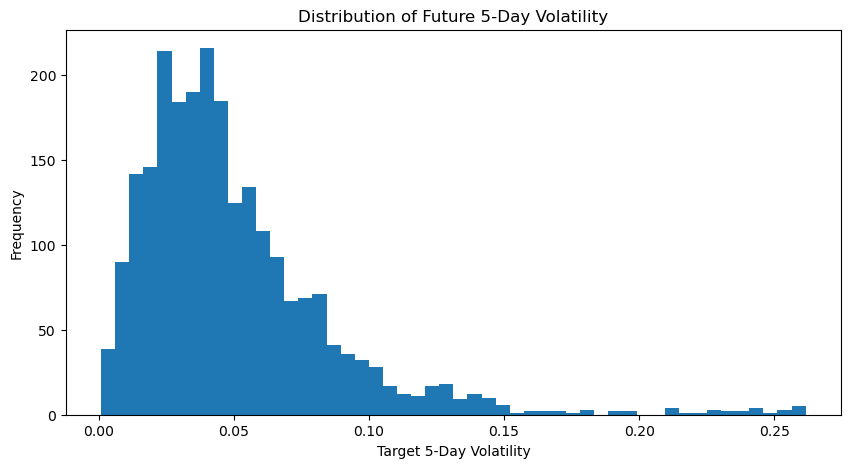

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(model_df[target], bins=50)

plt.title("Distribution of Future 5-Day Volatility")
plt.xlabel("Target 5-Day Volatility")
plt.ylabel("Frequency")

plt.show()

In [9]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training samples: 1890
Testing samples: 473

Training period:
2017-03-14 00:00:00 to 2024-10-11 00:00:00

Testing period:
2024-10-14 00:00:00 to 2026-08-31 00:00:00


In [10]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1890, 12)
X_test shape: (473, 12)
y_train shape: (1890,)
y_test shape: (473,)


In [11]:
baseline_prediction = y_train.mean()

baseline_pred = np.full(
    len(y_test),
    baseline_prediction
)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline Mean Prediction:", baseline_prediction)
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline Mean Prediction: 0.0497513702385868
Baseline MAE: 0.026714999769836493
Baseline RMSE: 0.0387147126332805


In [12]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression training completed.")

Linear Regression training completed.


In [13]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.02675553569816017
Linear Regression RMSE: 0.05515344410158669


In [14]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    "coefficient",
    key=abs,
    ascending=False
)

display(coefficients)

,feature,coefficient
1,log_return,-107.996782
3,price_range,4.709414
11,change_pct,1.082692
2,intraday_return,0.466763
8,drawdown,-0.131564
7,ma_50,-0.012955
0,daily_return,0.010827
4,ma_5,0.009929
6,ma_20,0.007806
10,change,-0.005953


In [15]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [16]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.026884084076258183
Random Forest RMSE: 0.042333151736991176


In [17]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

display(results)

,Model,MAE,RMSE
0,Baseline,0.026715,0.038715
1,Linear Regression,0.026756,0.055153
2,Random Forest,0.026884,0.042333


In [18]:
results_path = "../data/processed/usd_inr_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully.")
print(results_path)

Model results saved successfully.
../data/processed/usd_inr_initial_model_results.csv


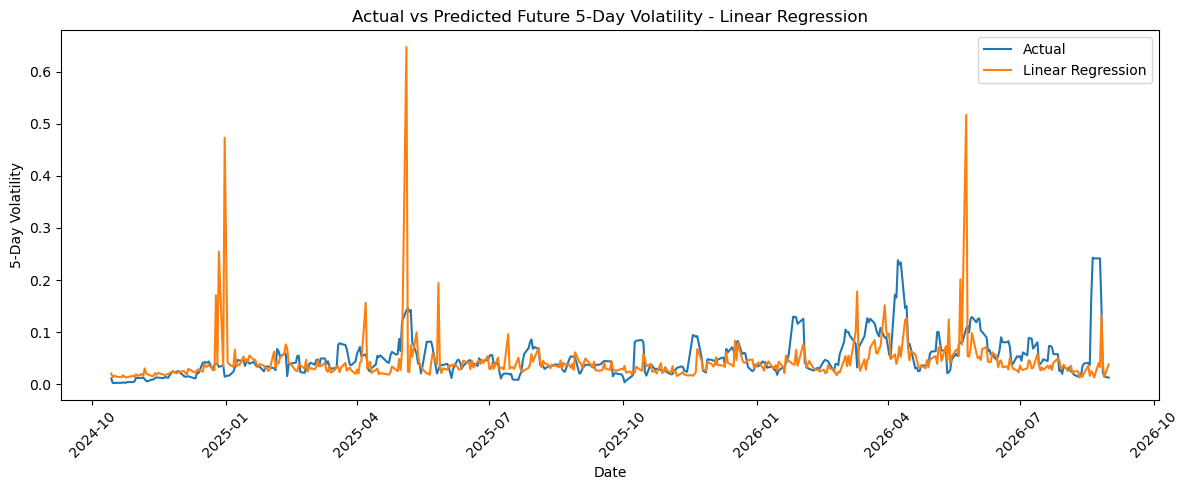

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_df["date"],
    y_test.values,
    label="Actual"
)

plt.plot(
    test_df["date"],
    linear_pred,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Future 5-Day Volatility - Linear Regression")
plt.xlabel("Date")
plt.ylabel("5-Day Volatility")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

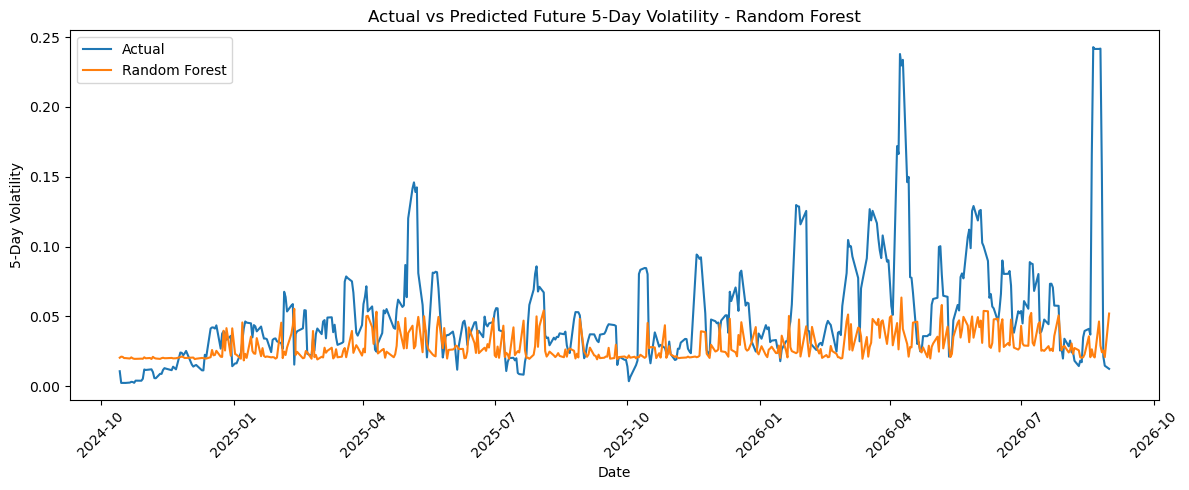

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_df["date"],
    y_test.values,
    label="Actual"
)

plt.plot(
    test_df["date"],
    rf_pred,
    label="Random Forest"
)

plt.title("Actual vs Predicted Future 5-Day Volatility - Random Forest")
plt.xlabel("Date")
plt.ylabel("5-Day Volatility")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

,feature,importance
3,price_range,0.407835
7,ma_50,0.201629
8,drawdown,0.076263
6,ma_20,0.070282
4,ma_5,0.057389
5,ma_10,0.048066
9,previous_close,0.047019
2,intraday_return,0.040711
10,change,0.015669
11,change_pct,0.012138


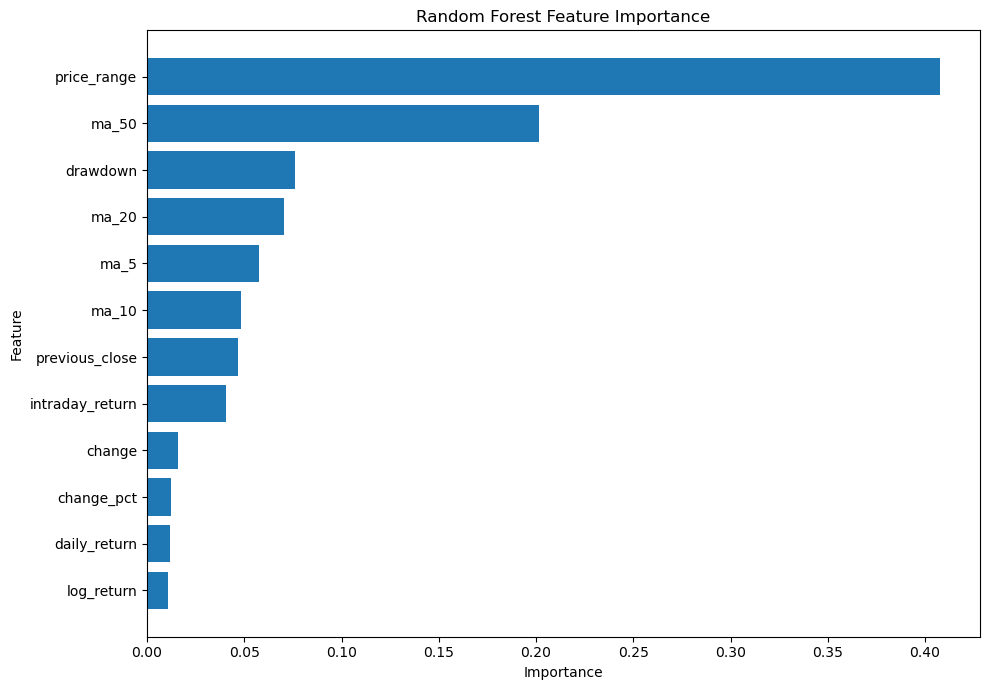

In [22]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [23]:
importance_path = "../data/processed/usd_inr_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully.")
print(importance_path)

Feature importance saved successfully.
../data/processed/usd_inr_random_forest_feature_importance.csv


In [24]:
predictions = pd.DataFrame({
    "date": test_df["date"],
    "actual_5d_volatility": y_test.values,
    "baseline_prediction": baseline_pred,
    "linear_regression_prediction": linear_pred,
    "random_forest_prediction": rf_pred
})

display(predictions.head(10))

,date,actual_5d_volatility,baseline_prediction,linear_regression_prediction,random_forest_prediction
1890,2024-10-14,0.010820,0.049751,0.020428,0.020500
1891,2024-10-15,0.002454,0.049751,0.013358,0.021253
1892,2024-10-16,0.002492,0.049751,0.016062,0.021085
1893,2024-10-17,0.002452,0.049751,0.015326,0.020238
1894,2024-10-18,0.002442,0.049751,0.014153,0.020218
1895,2024-10-21,0.002691,0.049751,0.013457,0.019922
1896,2024-10-22,0.003207,0.049751,0.017503,0.020742
1897,2024-10-23,0.003115,0.049751,0.014120,0.020048
1898,2024-10-24,0.002526,0.049751,0.013186,0.019703
1899,2024-10-25,0.004075,0.049751,0.013310,0.019683


In [25]:
predictions_path = "../data/processed/usd_inr_model_predictions.csv"

predictions.to_csv(
    predictions_path,
    index=False
)

print("Predictions saved successfully.")
print(predictions_path)

Predictions saved successfully.
../data/processed/usd_inr_model_predictions.csv


In [26]:
print("=" * 60)
print("USD/INR INITIAL MODEL EXPERIMENT SUMMARY")
print("=" * 60)

print("\nDataset:")
print("USD/INR")

print("\nTarget:")
print("Next 5-Trading-Day Realized Volatility")

print("\nTraining samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nModel Performance:")
display(results)

print("\nBest model by MAE:")
print(results.loc[results["MAE"].idxmin(), "Model"])

print("\nBest model by RMSE:")
print(results.loc[results["RMSE"].idxmin(), "Model"])

print("\nExperiment completed successfully.")

USD/INR INITIAL MODEL EXPERIMENT SUMMARY

Dataset:
USD/INR

Target:
Next 5-Trading-Day Realized Volatility

Training samples: 1890
Testing samples: 473

Model Performance:


,Model,MAE,RMSE
0,Baseline,0.026715,0.038715
1,Linear Regression,0.026756,0.055153
2,Random Forest,0.026884,0.042333



Best model by MAE:
Baseline

Best model by RMSE:
Baseline

Experiment completed successfully.
